# Partie 4. Monte Carlo, estimation sur données, backtesting

Mesurer la précision d'une simulation, ajuster une loi sur des données, backtester une VaR, puis tout assembler dans une étude de cas.

*Cours « Probabilités pour la gestion des risques », M1 GRAF. Exécutez les cellules dans l'ordre (Maj + Entrée).*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate
from math import comb, perm, factorial, log, exp

rng = np.random.default_rng(42)   # graine : memes resultats a chaque execution

## Chapitre 12. Précision d'une simulation

In [2]:
n = 10_000
x = rng.exponential(1000, size=n)
p = np.mean(x > 2000); se = np.sqrt(p*(1-p)/n)
print('P(X>2000) :', p, 'IC95 :', (p - 1.96*se, p + 1.96*se), '| exact', np.exp(-2))
v = np.quantile(x, 0.99, method='inverted_cdf'); t = x[x > v].mean()
vs, ts = [], []
for _ in range(2000):
    y = rng.choice(x, size=n, replace=True)
    q = np.quantile(y, 0.99, method='inverted_cdf'); vs.append(q); ts.append(y[y > q].mean())
print('VaR 99 % :', v, np.percentile(vs, [2.5, 97.5]), '| exact', 1000*np.log(100))
print('TVaR 99 % :', t, np.percentile(ts, [2.5, 97.5]), '| exact', 1000*np.log(100) + 1000)

P(X>2000) : 0.1332 IC95 : (np.float64(0.1265401011207677), np.float64(0.13985989887923234)) | exact 0.1353352832366127


VaR 99 % : 4574.601928562763 [4391.98991427 4731.70093322] | exact 4605.170185988091
TVaR 99 % : 5508.034581971339 [5247.24567553 5789.84614089] | exact 5605.170185988091


### La précision de la VaR simulée selon n

In [3]:
f = 0.01/1000
for n_ in [1_000, 10_000, 1_000_000]:
    print(n_, 'scenarios au-dela :', int(n_*0.01), '| ecart-type theorique :', round(np.sqrt(0.99*0.01/n_)/f, 1))
# verification empirique avec n = 10 000
res = [np.quantile(rng.exponential(1000, 10_000), 0.99, method='inverted_cdf') for _ in range(1000)]
print('ecart-type observe sur 1000 repetitions :', np.std(res))

1000 scenarios au-dela : 10 | ecart-type theorique : 314.6
10000 scenarios au-dela : 100 | ecart-type theorique : 99.5
1000000 scenarios au-dela : 10000 | ecart-type theorique : 9.9


ecart-type observe sur 1000 repetitions : 95.18040382190401


### [N3] Variables antithétiques

In [4]:
U = rng.random(5000)
simple = -1000*np.log(1 - rng.random(10_000))
paires = (-1000*np.log(1 - U) - 1000*np.log(U)) / 2
print('simple : se =', simple.std()/np.sqrt(10_000), '| antithetique : se =', paires.std()/np.sqrt(5000))

simple : se = 10.17258945768057 | antithetique : se = 5.955647553080163


### Deux normales corrélées

In [5]:
z1, z2 = rng.standard_normal(100_000), rng.standard_normal(100_000)
w = 0.5*z1 + np.sqrt(1 - 0.25)*z2
print('correlation :', np.corrcoef(z1, w)[0, 1])

correlation : 0.4998009880587996


## Chapitre 13. Quelle loi pour nos 20 sinistres ?

In [6]:
x20 = np.array([3, 4, 9, 12, 15, 18, 22, 28, 37, 45, 55, 61, 70, 78, 95, 140, 150, 310, 520, 980.])
E = stats.expon(scale=x20.mean())
mu, sigma = np.log(x20).mean(), np.log(x20).std()
L = stats.lognorm(s=sigma, scale=np.exp(mu))
print('Parametres : theta =', x20.mean(), '| mu =', mu, 'sigma =', sigma)
print('SciPy fit :', stats.expon.fit(x20, floc=0), stats.lognorm.fit(x20, floc=0))
v_h = np.quantile(x20, 0.9, method='inverted_cdf'); tv_h = x20[x20 > v_h].mean()
print('Historique : VaR90', v_h, 'TVaR90', tv_h)
for nom, loi in [('expo', E), ('lognormale', L)]:
    v = loi.ppf(0.9); tv = v + integrate.quad(loi.sf, v, np.inf)[0]/0.1
    print(f'{nom:10s} VaR90={v:7.1f} TVaR90={tv:7.1f} VaR99={loi.ppf(0.99):7.1f} KS p={stats.kstest(x20, loi.cdf).pvalue:.3f}')

Parametres : theta = 132.6 | mu = 3.8356903304514383 sigma = 1.4742111230295394
SciPy fit : (0.0, 132.6) (np.float64(1.4742111230295394), 0, np.float64(46.325396464018205))
Historique : VaR90 310.0 TVaR90 750.0
expo       VaR90=  305.3 TVaR90=  437.9 VaR99=  610.6 KS p=0.123
lognormale VaR90=  306.4 TVaR90=  791.5 VaR99= 1429.7 KS p=1.000


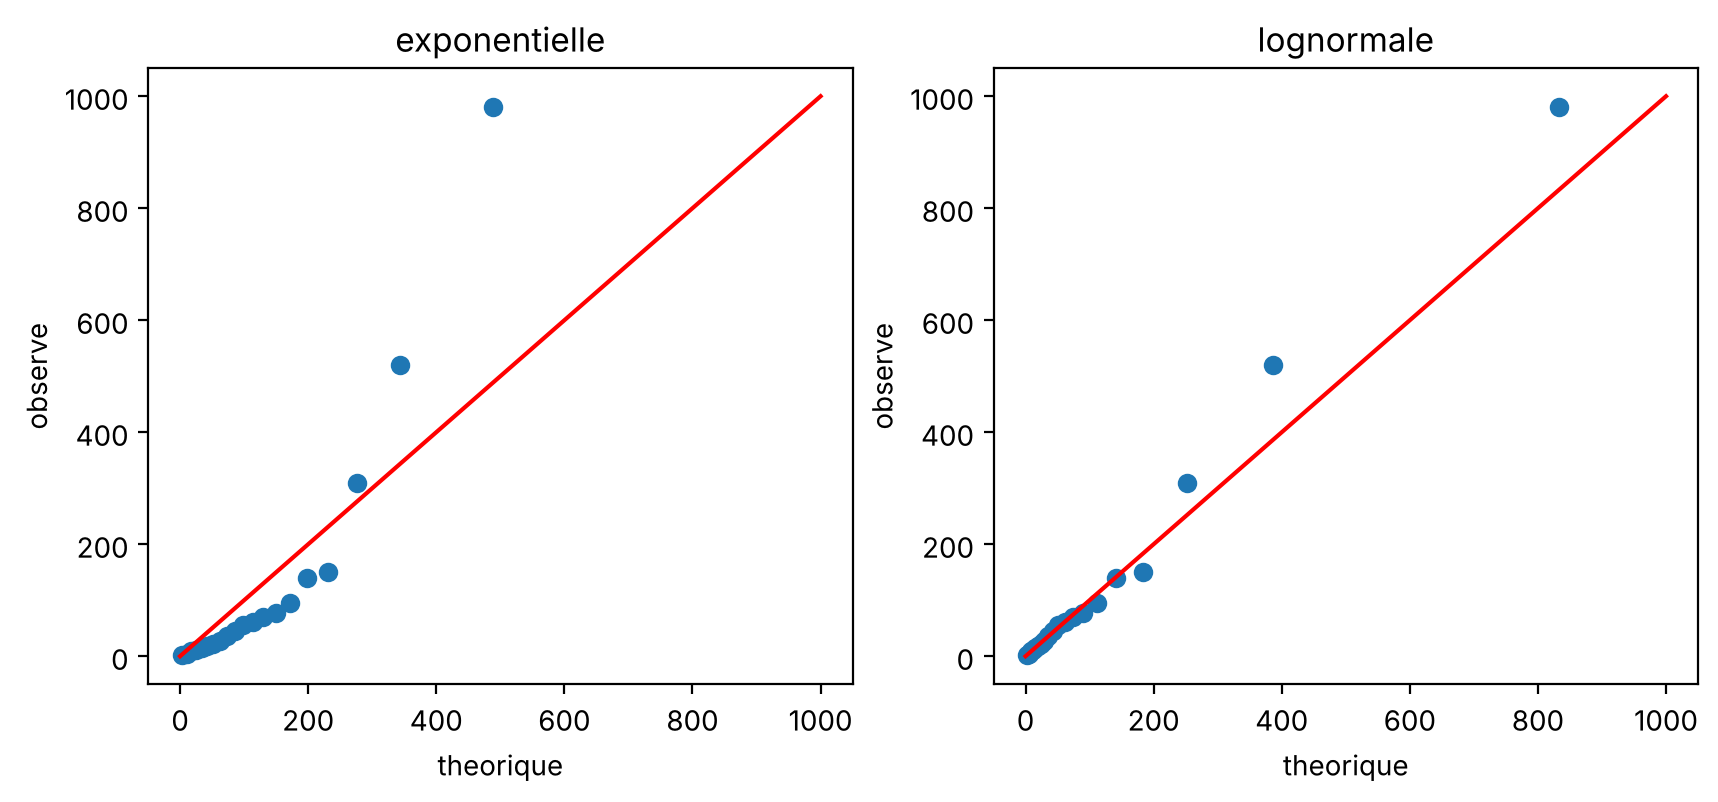

In [7]:
# QQ-plots
probs = (np.arange(1, 21) - 0.5)/20
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (nom, loi) in zip(ax, [('exponentielle', E), ('lognormale', L)]):
    a.scatter(loi.ppf(probs), np.sort(x20)); m = max(loi.ppf(probs).max(), 1000)
    a.plot([0, m], [0, m], 'r'); a.set_title(nom); a.set_xlabel('theorique'); a.set_ylabel('observe')
plt.show()

In [8]:
# Incertitude : bootstrap de la VaR 99 % lognormale
vb = []
for _ in range(5000):
    y = np.log(rng.choice(x20, 20)); vb.append(np.exp(y.mean() + y.std()*stats.norm.ppf(0.99)))
print('VaR 99 % lognormale :', L.ppf(0.99), '| IC95 bootstrap :', np.percentile(vb, [2.5, 97.5]))

VaR 99 % lognormale : 1429.6976143523134 | IC95 bootstrap : [ 361.8497063  4022.75453423]


## Chapitre 14. Backtesting

In [9]:
def kupiec(x, n, p):
    p_hat = x/n
    l0 = (n - x)*np.log(1 - p) + x*np.log(p)
    l1 = (n - x)*np.log(1 - p_hat) + (x*np.log(p_hat) if x > 0 else 0)
    LR = -2*(l0 - l1); return LR, stats.chi2.sf(LR, 1)

def zone_bale(x):
    return 'verte' if x <= 4 else ('jaune' if x <= 9 else 'rouge')

B = stats.binom(250, 0.01)
print('k  P(N=k)  P(N<=k)')
for k in range(11): print(k, round(B.pmf(k), 4), round(B.cdf(k), 4))
for x_ in [0, 2, 5, 7, 10]:
    LR, pv = kupiec(x_, 250, 0.01); print(f'{x_} exceptions : LR={LR:.2f} p={pv:.4f} zone {zone_bale(x_)}')

k  P(N=k)  P(N<=k)
0 0.0811 0.0811
1 0.2047 0.2858
2 0.2574 0.5432
3 0.2149 0.7581
4 0.1341 0.8922
5 0.0666 0.9588
6 0.0275 0.9863
7 0.0097 0.996
8 0.003 0.9989
9 0.0008 0.9997
10 0.0002 0.9999
0 exceptions : LR=5.03 p=0.0250 zone verte
2 exceptions : LR=0.11 p=0.7419 zone verte
5 exceptions : LR=1.96 p=0.1619 zone jaune
7 exceptions : LR=5.50 p=0.0190 zone jaune
10 exceptions : LR=12.96 p=0.0003 zone rouge


### Un modèle normal face à des pertes de Student(4)

In [10]:
rng7 = np.random.default_rng(7)
pertes = stats.t(4).rvs(250, random_state=rng7)/np.sqrt(2)
var_n = stats.norm.ppf(0.99)
x_ = int(np.sum(pertes > var_n)); print('exceptions observees :', x_, kupiec(x_, 250, 0.01), zone_bale(x_))
p_vrai = stats.t(4).sf(var_n*np.sqrt(2)); print('vraie probabilite d exception :', p_vrai)
for p_ in [0.01, p_vrai]:
    Bp = stats.binom(250, p_); print(f'p={p_:.4f} verte={Bp.cdf(4):.3f} jaune={Bp.cdf(9)-Bp.cdf(4):.3f} rouge={Bp.sf(9):.4f}')

# Puissance : sur 10 000 annees simulees, part des annees ou le modele faux est en zone verte
X = stats.t(4).rvs((10_000, 250), random_state=rng7)/np.sqrt(2)
print('part en zone verte :', np.mean((X > var_n).sum(axis=1) <= 4))

exceptions observees : 1 (np.float64(1.1764911353210774), np.float64(0.2780714900139528)) verte
vraie probabilite d exception : 0.015108424539233244
p=0.0100 verte=0.892 jaune=0.108 rouge=0.0003
p=0.0151 verte=0.673 jaune=0.322 rouge=0.0052
part en zone verte : 0.6758


## Étude de cas de synthèse

In [11]:
comptes = np.array([42, 51, 47, 55, 45])
lam = comptes.mean(); print('1) lambda =', lam, '| variance empirique =', comptes.var(ddof=1))
mu_, s_ = 6, 1
EX, EX2 = np.exp(mu_ + s_**2/2), np.exp(2*mu_ + 2*s_**2)
ES, sdS = lam*EX, np.sqrt(lam*EX2)
print('2) E[X] =', EX, 'E[X2] =', EX2, 'E[S] =', ES, 'sigma_S =', sdS)
print('3) VaR normale 99.5 % =', ES + stats.norm.ppf(0.995)*sdS)

rngc = np.random.default_rng(42); n_sim = 500_000
N = rngc.poisson(lam, n_sim); X = np.exp(rngc.normal(mu_, s_, N.sum())); an = np.repeat(np.arange(n_sim), N)
S = np.bincount(an, weights=X, minlength=n_sim)
v = np.quantile(S, 0.995, method='inverted_cdf')
print('4) VaR simulee =', v, '| TVaR =', S[S > v].mean())
print('5) capital =', v - S.mean())
Sr = np.bincount(an, weights=np.minimum(X, 3000), minlength=n_sim)
vr = np.quantile(Sr, 0.995, method='inverted_cdf')
prime = lam*integrate.quad(stats.lognorm(s=s_, scale=np.exp(mu_)).sf, 3000, np.inf)[0]
print('6) prime pure du traite =', prime, '| charge conservee moyenne =', Sr.mean(), '| VaR =', vr, '| capital =', vr - Sr.mean())

1) lambda = 48.0 | variance empirique = 26.0
2) E[X] = 665.1416330443618 E[X2] = 1202604.2841647768 E[S] = 31926.79838612937 sigma_S = 7597.697390651281
3) VaR normale 99.5 % = 51497.16996446595


4) VaR simulee = 56372.18158734674 | TVaR = 61456.76119206719
5) capital = 24452.778016979624


6) prime pure du traite = 1789.4919203474683 | charge conservee moyenne = 30128.06120403603 | VaR = 47960.36574164893 | capital = 17832.3045376129


## Vérification des exercices 12.1 à 14.2

In [12]:
p = 1080/40000; se = np.sqrt(p*(1-p)/40000); print('12.1 :', p, (p - 1.96*se, p + 1.96*se))
print('12.2 :', 0.995*0.005/(20*5e-6)**2)
print('13.1 :', comptes.mean(), comptes.var(ddof=1))
g = np.array([12, 15, 25, 11, 40.]); a_hat = 5/np.log(g/10).sum()
print('13.2 :', a_hat, a_hat*10/(a_hat - 1), 10*0.01**(-1/a_hat))
print('14.1 :', kupiec(6, 250, 0.01), zone_bale(6))
print('14.2 :', 250*0.025, stats.binom(250, 0.025).sf(11), kupiec(12, 250, 0.025))

12.1 : 0.027 (np.float64(0.025411583543273365), np.float64(0.028588416456726634))
12.2 : 497500.0
13.1 : 48.0 26.0
13.2 : 1.6746592920245538 24.822296406815152 156.41297450481036
14.1 : (np.float64(3.5553547710617437), np.float64(0.0593536189722889)) jaune
14.2 : 6.25 0.024702692774517143 (np.float64(4.29252483066719), np.float64(0.03828027841380207))
